<a href="https://colab.research.google.com/github/melekyakin/StockPriceForecastingLSTM/blob/main/StockPriceForecastingLSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Stock Price Forecasting with LSTM**

**Business Problem**

· Date: Represents the date of the relevant trading day.

· Open: Represents the opening price of the stock for the relevant trading day.

· High: Represents the highest price for the relevant trading day.

· Low: Represents the lowest price for the relevant trading day.

· Close: Represents the closing price of the stock on the relevant trading day.

· Adj Close: Represents the adjusted closing price of the stock for the relevant trading day.

· Volume: Represents the trading volume for the relevant trading day.

Translated with DeepL.com (free version)

Dataset: https://www.kaggle.com/timoboz/tesla-stock-data-from-2010-to-*2020*

In [17]:
#Libraries to be used in the data reading and processing step
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt


#Libraries to be used for model evaluation
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

#Libraries to be used for the model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,LSTM, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint,EarlyStopping

#Used to disable warnings
import warnings
warnings.filterwarnings('ignore')

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
tf.compat.v1.logging.set_verbosity(tf.compat.v1.logging.ERROR)

In [18]:
from google.colab import files

In [19]:
upload=files.upload()

Saving TSLA.csv to TSLA (2).csv


In [20]:
df = pd.read_csv("TSLA.csv")
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2010-06-29,19.000000,25.00,17.540001,23.889999,23.889999,18766300
1,2010-06-30,25.790001,30.42,23.299999,23.830000,23.830000,17187100
2,2010-07-01,25.000000,25.92,20.270000,21.959999,21.959999,8218800
3,2010-07-02,23.000000,23.10,18.709999,19.200001,19.200001,5139800
4,2010-07-06,20.000000,20.00,15.830000,16.110001,16.110001,6866900


In [21]:
def check_df(dataframe, head=5):
  print("#################### Shape ####################")
  print(dataframe.shape)
  print("#################### Types ####################")
  print(dataframe.dtypes)
  print("#################### Head ####################")
  print(dataframe.head(head))
  print("#################### Tail ####################")
  print(dataframe.tail(head))
  print("#################### NA ####################")
  print(dataframe.isnull().sum())
  print("#################### Quantiles ####################")
  print(dataframe.quantile([0, 0.05, 0.50, 0.95, 0.99, 1], numeric_only=True).T)

In [22]:
check_df(df)

#################### Shape ####################
(2416, 7)
#################### Types ####################
Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object
#################### Head ####################
         Date       Open   High        Low      Close  Adj Close    Volume
0  2010-06-29  19.000000  25.00  17.540001  23.889999  23.889999  18766300
1  2010-06-30  25.790001  30.42  23.299999  23.830000  23.830000  17187100
2  2010-07-01  25.000000  25.92  20.270000  21.959999  21.959999   8218800
3  2010-07-02  23.000000  23.10  18.709999  19.200001  19.200001   5139800
4  2010-07-06  20.000000  20.00  15.830000  16.110001  16.110001   6866900
#################### Tail ####################
            Date        Open        High         Low       Close   Adj Close  \
2411  2020-01-28  568.489990  576.809998  558.080017  566.900024  566.900024   
2412  2020-01-29  575.690002 

In [23]:
df["Date"]= pd.to_datetime(df["Date"])
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2010-06-29,19.000000,25.00,17.540001,23.889999,23.889999,18766300
1,2010-06-30,25.790001,30.42,23.299999,23.830000,23.830000,17187100
2,2010-07-01,25.000000,25.92,20.270000,21.959999,21.959999,8218800
3,2010-07-02,23.000000,23.10,18.709999,19.200001,19.200001,5139800
4,2010-07-06,20.000000,20.00,15.830000,16.110001,16.110001,6866900


In [24]:
tesla_df = df[["Date","Close"]]
tesla_df.head()

,Date,Close
0,2010-06-29,23.889999
1,2010-06-30,23.830000
2,2010-07-01,21.959999
3,2010-07-02,19.200001
4,2010-07-06,16.110001


In [25]:
print("Minimum Tarih:", tesla_df["Date"].min())
print("Maksimum Tarih:", tesla_df["Date"].max())

Minimum Tarih: 2010-06-29 00:00:00
Maksimum Tarih: 2020-02-03 00:00:00


In [26]:
tesla_df.index = tesla_df["Date"]
tesla_df

,Date,Close
Date,,
2010-06-29,2010-06-29,23.889999
2010-06-30,2010-06-30,23.830000
2010-07-01,2010-07-01,21.959999
2010-07-02,2010-07-02,19.200001
2010-07-06,2010-07-06,16.110001
...,...,...
2020-01-28,2020-01-28,566.900024
2020-01-29,2020-01-29,580.989990
2020-01-30,2020-01-30,640.809998


In [27]:
tesla_df.drop("Date",axis = 1, inplace=True)
tesla_df

,Close
Date,
2010-06-29,23.889999
2010-06-30,23.830000
2010-07-01,21.959999
2010-07-02,19.200001
2010-07-06,16.110001
...,...
2020-01-28,566.900024
2020-01-29,580.989990
2020-01-30,640.809998


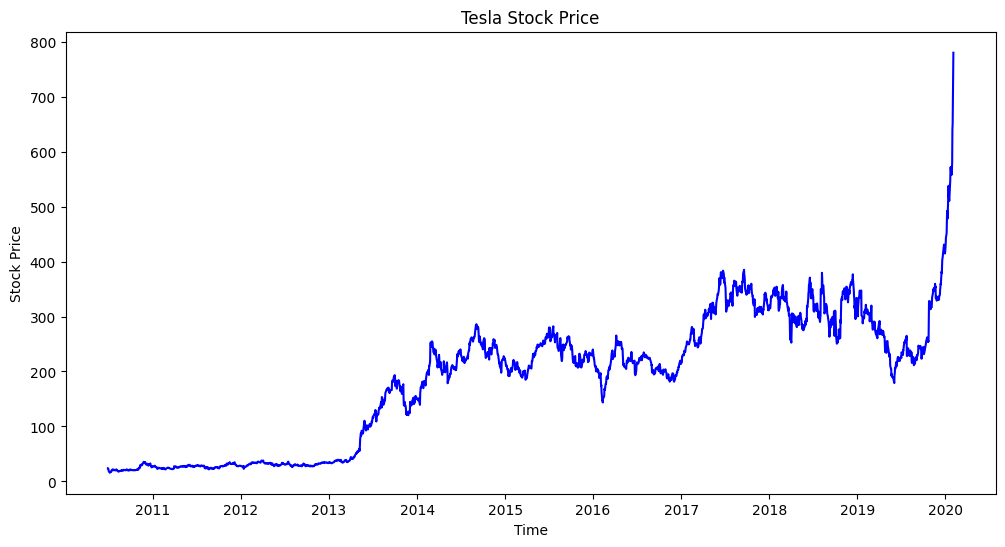

In [28]:
result_df = tesla_df.copy()
plt.figure(figsize=(12,6))
plt.plot(tesla_df['Close'], color ='blue');
plt.ylabel('Stock Price')
plt.title('Tesla Stock Price')
plt.xlabel('Time')
plt.show()

In [29]:
tesla_df[0:5]

,Close
Date,
2010-06-29,23.889999
2010-06-30,23.830000
2010-07-01,21.959999
2010-07-02,19.200001
2010-07-06,16.110001


In [30]:
tesla_df = tesla_df.astype('float32')

In [31]:
def split_data(dataframe, test_size):
  pos = int(round(len(dataframe)*(1-test_size)))
  train=dataframe[:pos]
  test=dataframe[pos:]
  return train, test, pos

In [32]:
train, test, pos = split_data(tesla_df, 0.20)
print(train.shape, test.shape)

(1933, 1) (483, 1)


In [33]:
scaler_train = MinMaxScaler(feature_range=(0,1))
train = scaler_train.fit_transform(train)
scaler_test=MinMaxScaler(feature_range=(0,1))
test = scaler_test.fit_transform(test)
train[0:5]

array([[0.02191224],
       [0.02174973],
       [0.01668472],
       [0.0092091 ],
       [0.00083966]], dtype=float32)

In [34]:
test[0:5]

array([[0.25685903],
       [0.24829045],
       [0.25511202],
       [0.24978784],
       [0.2465767 ]], dtype=float32)

In [35]:
def create_features(data, lookback):
    X, Y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i, 0])
        Y.append(data[i, 0])

    return np.array(X), np.array(Y)


In [36]:
lookback = 20

In [37]:
#Train Dataset
X_train, y_train = create_features(train, lookback)

#Test Dataset
X_test, y_test = create_features(test, lookback)

In [38]:
print(X_train.shape,y_train.shape, X_test.shape, y_test.shape)

(1913, 20) (1913,) (463, 20) (463,)


In [39]:
X_train[0:5]

array([[0.02191224, 0.02174973, 0.01668472, 0.0092091 , 0.00083966,
        0.        , 0.00449621, 0.00433369, 0.0033857 , 0.00633803,
        0.01094258, 0.011078  , 0.01310942, 0.0165493 , 0.01218851,
        0.01197183, 0.01408451, 0.01486999, 0.01394908, 0.01286566],
       [0.02174973, 0.01668472, 0.0092091 , 0.00083966, 0.        ,
        0.00449621, 0.00433369, 0.0033857 , 0.00633803, 0.01094258,
        0.011078  , 0.01310942, 0.0165493 , 0.01218851, 0.01197183,
        0.01408451, 0.01486999, 0.01394908, 0.01286566, 0.01332611],
       [0.01668472, 0.0092091 , 0.00083966, 0.        , 0.00449621,
        0.00433369, 0.0033857 , 0.00633803, 0.01094258, 0.011078  ,
        0.01310942, 0.0165493 , 0.01218851, 0.01197183, 0.01408451,
        0.01486999, 0.01394908, 0.01286566, 0.01332611, 0.01232395],
       [0.0092091 , 0.00083966, 0.        , 0.00449621, 0.00433369,
        0.0033857 , 0.00633803, 0.01094258, 0.011078  , 0.01310942,
        0.0165493 , 0.01218851, 0.01197183, 0

In [40]:
y_train[0:5]

array([0.01332611, 0.01232395, 0.01121344, 0.01386782, 0.01665764],
      dtype=float32)

In [41]:
X_train = np.reshape(X_train,(X_train.shape[0],1, X_train.shape[1]))
X_test = np.reshape(X_test,(X_test.shape[0],1, X_test.shape[1]))

y_train = y_train.reshape(-1,1)
y_test = y_test.reshape(-1,1)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape )

(1913, 1, 20) (1913, 1) (463, 1, 20) (463, 1)


In [42]:
model =Sequential()
model.add(LSTM(units =50,
               activation='relu',
               input_shape = (X_train.shape[1],lookback)))
model.add(Dropout(0.2))
model.add(Dense(1))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        14,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,251 (55.67 KB)

 Trainable params: 14,251 (55.67 KB)

 Non-trainable params: 0 (0.00 B)

In [43]:
#Configuring Optimization and Evaluation Metrics
model.compile(loss ='mean_squared_error', optimizer ='adam')
callbacks = [EarlyStopping(monitor='val_loss',patience=3,verbose=1, mode="min"),
             ModelCheckpoint(filepath='mymodel.h5', monitor='val_loss', mode='min',
             save_best_only=True, save_weights_only=False, verbose=1)]

In [44]:
history = model.fit(x=X_train,
                    y=y_train,
                    epochs=100,
                    batch_size=20,
                    validation_data=(X_test, y_test),
                    callbacks=callbacks,
                    shuffle=False)

Epoch 1/100
95/96 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0037
Epoch 1: val_loss improved from None to 0.00391, saving model to mymodel.h5



Epoch 1: finished saving model to mymodel.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0076 - val_loss: 0.0039
Epoch 2/100
83/96 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0039
Epoch 2: val_loss improved from 0.00391 to 0.00349, saving model to mymodel.h5



Epoch 2: finished saving model to mymodel.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0068 - val_loss: 0.0035
Epoch 3/100
77/96 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0029
Epoch 3: val_loss did not improve from 0.00349
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0056 - val_loss: 0.0036
Epoch 4/100
91/96 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0020
Epoch 4: val_loss improved from 0.00349 to 0.00330, saving model to mymodel.h5



Epoch 4: finished saving model to mymodel.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0051 - val_loss: 0.0033
Epoch 5/100
93/96 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0021
Epoch 5: val_loss improved from 0.00330 to 0.00308, saving model to mymodel.h5



Epoch 5: finished saving model to mymodel.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0053 - val_loss: 0.0031
Epoch 6/100
79/96 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0018
Epoch 6: val_loss improved from 0.00308 to 0.00284, saving model to mymodel.h5


...


Epoch 10: finished saving model to mymodel.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0045 - val_loss: 0.0023
Epoch 11/100
83/96 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0017
Epoch 11: val_loss improved from 0.00226 to 0.00226, saving model to mymodel.h5



Epoch 11: finished saving model to mymodel.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0044 - val_loss: 0.0023
Epoch 12/100
84/96 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0016
Epoch 12: val_loss did not improve from 0.00226
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0042 - val_loss: 0.0023
Epoch 13/100
76/96 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0015
Epoch 13: val_loss improved from 0.00226 to 0.00213, saving model to mymodel.h5



Epoch 13: finished saving model to mymodel.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0040 - val_loss: 0.0021
Epoch 14/100
78/96 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0015
Epoch 14: val_loss improved from 0.00213 to 0.00196, saving model to mymodel.h5



Epoch 14: finished saving model to mymodel.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0045 - val_loss: 0.0020
Epoch 15/100
92/96 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0016
Epoch 15: val_loss improved from 0.00196 to 0.00190, saving model to mymodel.h5



Epoch 15: finished saving model to mymodel.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0040 - val_loss: 0.0019
Epoch 16/100
84/96 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0015
Epoch 16: val_loss did not improve from 0.00190
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0041 - val_loss: 0.0023
Epoch 17/100
91/96 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0018
Epoch 17: val_loss did not improve from 0.00190
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0043 - val_loss: 0.0030
Epoch 18/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0021
Epoch 18: val_loss did not improve from 0.00190
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0044 - val_loss: 0.0025
Epoch 18: early stopping


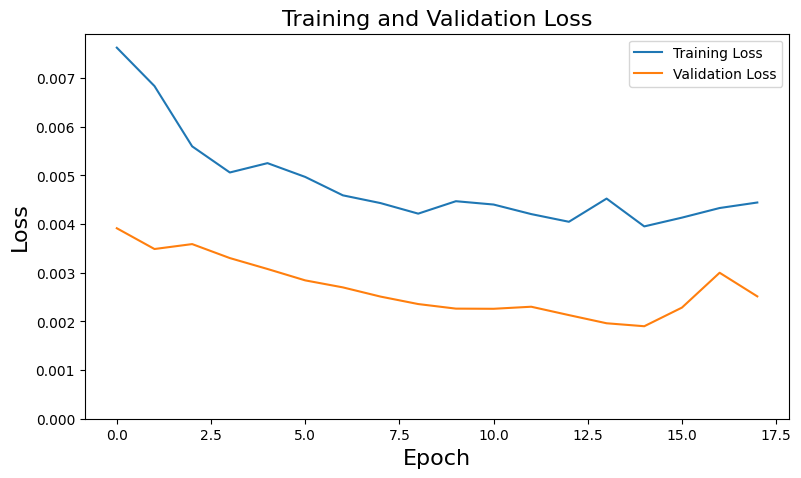

In [45]:
plt.figure(figsize=(20,5))
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend(loc='upper right')
plt.xlabel('Epoch', fontsize=16)
plt.ylabel('Loss', fontsize=16)
plt.ylim([0,max(plt.ylim())])
plt.title('Training and Validation Loss', fontsize=16)
plt.show()

In [46]:
loss=model.evaluate(X_test, y_test, batch_size=20)
print("\nTest loss: %.1f%%" % (100.0 * loss))

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0025 

Test loss: 0.3%


In [47]:
train_predict = model.predict(X_train)
test_predict = model.predict(X_test)

train_predict = scaler_train.inverse_transform(train_predict)
test_predict = scaler_test.inverse_transform(test_predict)

y_train = scaler_train.inverse_transform(y_train)
y_test = scaler_test.inverse_transform(y_test)

60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


In [48]:
train_rmse=np.sqrt(mean_squared_error(y_train,train_predict))

In [49]:
test_rmse=np.sqrt(mean_squared_error(y_test,test_predict))

In [50]:
print(f"Train RMSE: {train_rmse}")
print(f"Test RMSE: {test_rmse}")


Train RMSE: 13.337491785706526
Test RMSE: 30.13612508529008


In [51]:
train_prediction_df = result_df[lookback:pos]
train_prediction_df["Predicted"] = train_predict
train_prediction_df.head()

,Close,Predicted
Date,,
2010-07-28,20.719999,37.550346
2010-07-29,20.350000,37.550346
2010-07-30,19.940001,37.550346
2010-08-02,20.920000,37.550346
2010-08-03,21.950001,37.550346


In [52]:
test_prediction_df = result_df[pos+lookback:]
test_prediction_df["Predicted"] = test_predict
test_prediction_df.head()

,Close,Predicted
Date,,
2018-04-03,267.529999,318.843567
2018-04-04,286.940002,317.428131
2018-04-05,305.720001,317.040100
2018-04-06,299.299988,319.538635
2018-04-09,289.660004,318.837585


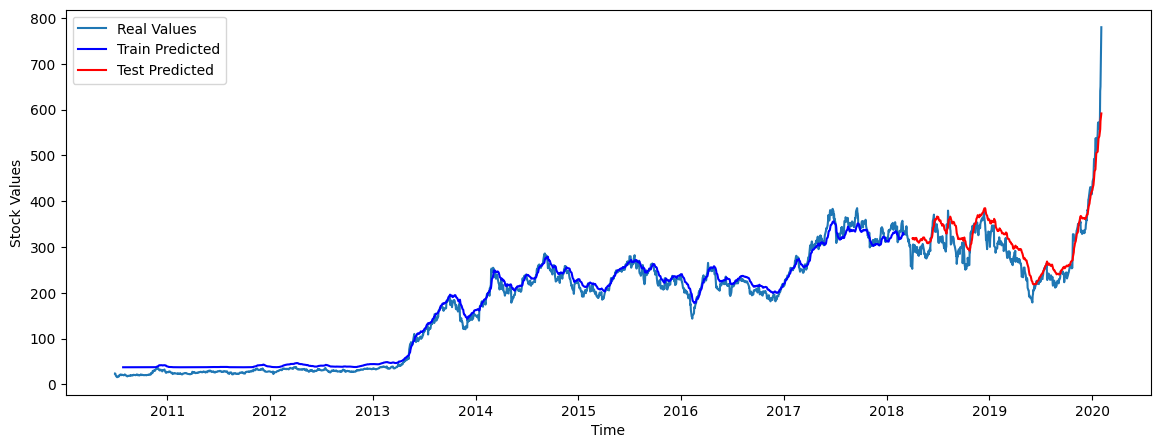

In [53]:
plt.figure(figsize=(14, 5))
plt.plot(result_df, label='Real Values')
plt.plot(train_prediction_df["Predicted"], color='blue', label='Train Predicted')
plt.plot(test_prediction_df["Predicted"], color='red', label='Test Predicted')
plt.xlabel('Time')
plt.ylabel('Stock Values')
plt.legend()
plt.show()